**Problem 2c**

rho = 4.0000
Largest difference = 0.0036
Largest difference occurs at state 6
Simulated time average = 4.0366
Theoretical mean = 4.0000
Smallest fleet size = 9
P(X > 9) = 0.0081
P(X > 8) = 0.0214


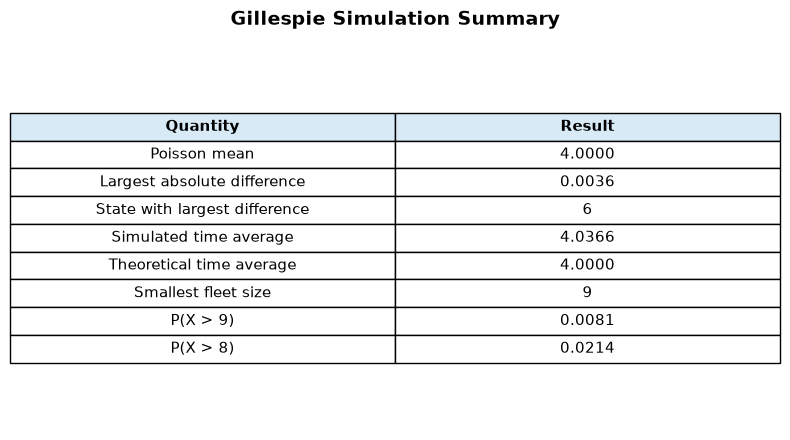

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

rng = np.random.default_rng(34)

lamb = 12
mu = 3
rho = lamb / mu
T = 500

t = 0
state = 0
time_spent = []

while t < T:
    if state >= len(time_spent):
        time_spent.append(0)

    rate = lamb + state * mu
    wait = rng.exponential(1 / rate)

    if t + wait >= T:
        time_spent[state] += T - t
        break

    time_spent[state] += wait
    t += wait

    probability_up = lamb / rate

    if rng.random() < probability_up:
        state += 1
    else:
        state -= 1

n_max = max(
    len(time_spent) - 1,
    int(poisson.ppf(0.999999, rho))
)

time_spent = np.pad(
    time_spent,
    (0, n_max + 1 - len(time_spent))
)

states = np.arange(n_max + 1)

simulated = time_spent / T
theoretical = poisson.pmf(states, rho)
differences = np.abs(simulated - theoretical)

largest_difference = np.max(differences)
largest_state = states[np.argmax(differences)]

time_average = np.sum(states * simulated)

c = 0

while poisson.sf(c, rho) > 0.01:
    c += 1

print(f"rho = {rho:.4f}")
print(f"Largest difference = {largest_difference:.4f}")
print(f"Largest difference occurs at state {largest_state}")
print(f"Simulated time average = {time_average:.4f}")
print(f"Theoretical mean = {rho:.4f}")
print(f"Smallest fleet size = {c}")
print(f"P(X > {c}) = {poisson.sf(c, rho):.4f}")
print(f"P(X > {c - 1}) = {poisson.sf(c - 1, rho):.4f}")

#table making
summary_rows = [
    ["Poisson mean", f"{rho:.4f}"],
    ["Largest absolute difference", f"{largest_difference:.4f}"],
    ["State with largest difference", f"{largest_state}"],
    ["Simulated time average", f"{time_average:.4f}"],
    ["Theoretical time average", f"{rho:.4f}"],
    ["Smallest fleet size", f"{c}"],
    [f"P(X > {c})", f"{poisson.sf(c, rho):.4f}"],
    [f"P(X > {c - 1})", f"{poisson.sf(c - 1, rho):.4f}"]
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axis("off")

summary_table = ax.table(
    cellText=summary_rows,
    colLabels=["Quantity", "Result"],
    cellLoc="center",
    loc="center"
)

summary_table.auto_set_font_size(False)
summary_table.set_fontsize(11)
summary_table.scale(1, 1.5)

for j in range(2):
    summary_table[(0, j)].set_facecolor("#D9EAF7")
    summary_table[(0, j)].set_text_props(weight="bold")

plt.title(
    "Gillespie Simulation Summary",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "2c_simulation_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

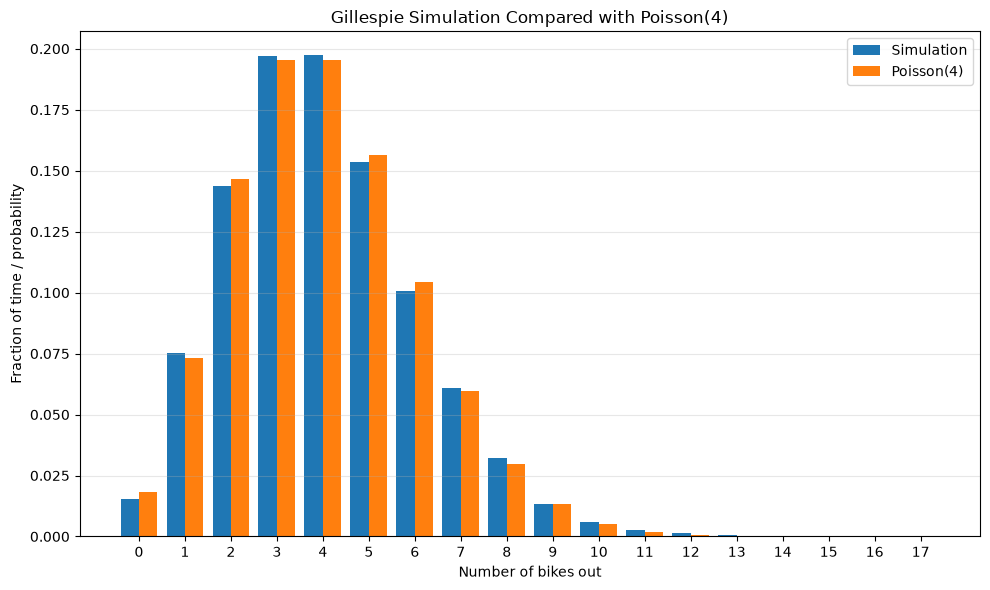

In [6]:
width = 0.4

plt.figure(figsize=(10, 6))

plt.bar(
    states - width / 2,
    simulated,
    width=width,
    label="Simulation"
)

plt.bar(
    states + width / 2,
    theoretical,
    width=width,
    label="Poisson(4)"
)

plt.xlabel("Number of bikes out")
plt.ylabel("Fraction of time / probability")
plt.title("Gillespie Simulation Compared with Poisson(4)")
plt.xticks(states)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "2c_bike_share_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

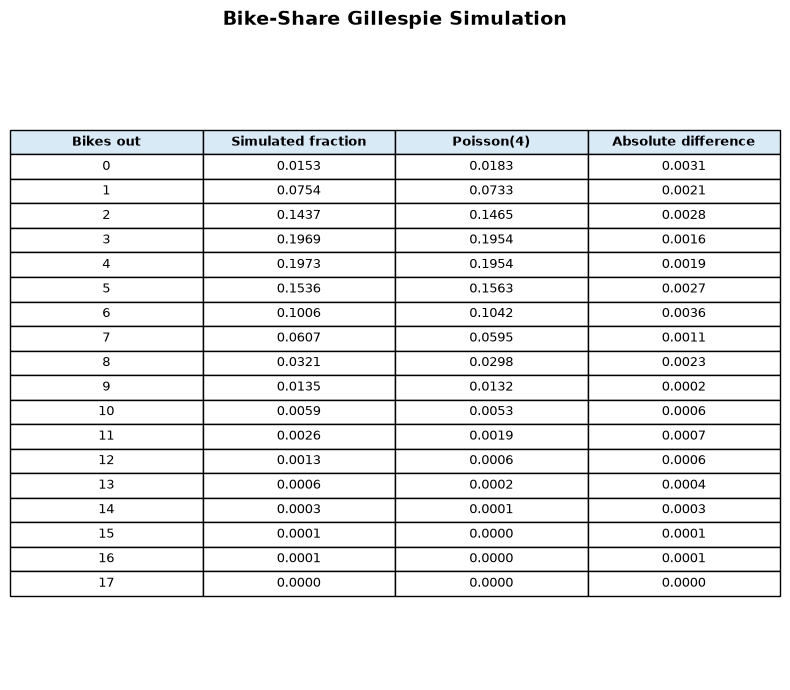

In [7]:
#print up
table_rows = []

for n in states:
    table_rows.append([
        str(n),
        f"{simulated[n]:.4f}",
        f"{theoretical[n]:.4f}",
        f"{differences[n]:.4f}"
    ])

fig, ax = plt.subplots(figsize=(8, 7))
ax.axis("off")

table = ax.table(
    cellText=table_rows,
    colLabels=[
        "Bikes out",
        "Simulated fraction",
        "Poisson(4)",
        "Absolute difference"
    ],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.25)

for j in range(4):
    table[(0, j)].set_facecolor("#D9EAF7")
    table[(0, j)].set_text_props(weight="bold")

plt.title(
    "Bike-Share Gillespie Simulation",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "2c_bike_share_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()